In [7]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

conn = sqlite3.connect(r"C:\Users\umrrr\OneDrive\Desktop\airtel-telecom-analytics\data\raw\airtel.db")

def q(query):
    return pd.read_sql_query(query, conn)

**Q1. Check customer_features table**

In [8]:
q("""
PRAGMA table_info(customer_features);
""")

,cid,name,type,notnull,dflt_value,pk
0,0,customer_id,INT,0,None,0
1,1,activation_date,TEXT,0,None,0
2,2,tenure_days,INT,0,None,0
3,3,tenure_years,INT,0,None,0
4,4,observed_days,INT,0,None,0
5,5,circle_name,TEXT,0,None,0
6,6,region,TEXT,0,None,0
7,7,plan_name,TEXT,0,None,0
8,8,plan_type,TEXT,0,None,0
9,9,price_inr,INT,0,None,0


**Q2. Recharge table schema**

In [9]:
q("""
PRAGMA table_info(recharges);
""")

,cid,name,type,notnull,dflt_value,pk
0,0,recharge_id,INTEGER,0,None,0
1,1,customer_id,INTEGER,0,None,0
2,2,recharge_date,TEXT,0,None,0
3,3,amount_inr,INTEGER,0,None,0
4,4,plan_id,INTEGER,0,None,0
5,5,channel,TEXT,0,None,0
6,6,txn_type,TEXT,0,None,0


**Q3. Total customers**

In [10]:
q("""
SELECT COUNT(*) AS total_customers
FROM customer_features;
""")

,total_customers
0,22000


**Q4. Unique customers**

In [11]:
q("""
SELECT COUNT(DISTINCT customer_id) AS unique_customers
FROM customer_features;
""")

,unique_customers
0,22000


**Q5. Duplicate customer IDs**

In [12]:
q("""
SELECT customer_id, COUNT(*) AS count
FROM customer_features
GROUP BY customer_id
HAVING COUNT(*) > 1;
""")

,customer_id,count


**Q6. Missing customer IDs**

In [13]:
q("""
SELECT COUNT(*) AS missing_customer_ids
FROM customer_features
WHERE customer_id IS NULL;
""")

,missing_customer_ids
0,0


**Q7. Missing recharge dates**

In [14]:
q("""
SELECT COUNT(*) AS missing_dates
FROM recharges
WHERE recharge_date IS NULL;
""")

,missing_dates
0,0


**Q8. Missing recharge amounts**

In [15]:
q("""
SELECT COUNT(*) AS missing_amounts
FROM recharges
WHERE amount_inr IS NULL;
""")

,missing_amounts
0,0


**Q9. Zero or negative recharge amounts**

In [16]:
q("""
SELECT *
FROM recharges
WHERE amount_inr <= 0;
""")


,recharge_id,customer_id,recharge_date,amount_inr,plan_id,channel,txn_type


**Q10. Recharge dates outside the analysis period**

In [17]:
q("""
SELECT *
FROM recharges
WHERE recharge_date < '2025-01-01'
   OR recharge_date >= '2025-07-01';
""")

,recharge_id,customer_id,recharge_date,amount_inr,plan_id,channel,txn_type
0,1,1,2023-04-23,299,4,Retailer,Recharge
1,2,1,2023-05-21,299,4,USSD,Recharge
2,3,1,2023-06-17,299,4,Website,Recharge
3,4,1,2023-07-17,299,4,Airtel App,Recharge
4,5,1,2023-08-12,299,4,Website,Recharge
...,...,...,...,...,...,...,...
324391,408083,21999,2024-09-29,399,6,Website,Recharge
324392,408084,21999,2024-10-27,399,6,USSD,Recharge
324393,408085,21999,2024-11-24,399,6,Retailer,Recharge
324394,408086,21999,2024-12-20,399,6,USSD,Recharge


**Q11. Total recharge per customer**

In [18]:
recharge_summary = q("""
SELECT
    customer_id,
    COUNT(*) AS recharge_count,
    SUM(amount_inr) AS total_recharge,
    AVG(amount_inr) AS average_recharge,
    COUNT(DISTINCT strftime('%Y-%m', recharge_date))
        AS active_recharge_months
FROM recharges
WHERE recharge_date >= '2025-01-01'
AND recharge_date < '2025-07-01'
AND amount_inr > 0
GROUP BY customer_id;
""")

recharge_summary.head()

,customer_id,recharge_count,total_recharge,average_recharge,active_recharge_months
0,1,3,897,299.0,3
1,2,2,198,99.0,1
2,3,6,5073,845.5,6
3,5,2,1438,719.0,2
4,6,12,1188,99.0,6


**Q12. LEFT JOIN**

In [19]:
validation_df = q("""
SELECT
    c.customer_id,
    c.is_churned,
    c.connection_type,
    c.tenure_days,
    c.complaint_count,

    COALESCE(r.recharge_count, 0) AS recharge_count,
    COALESCE(r.total_recharge, 0) AS total_recharge,
    r.average_recharge,
    COALESCE(r.active_recharge_months, 0)
        AS active_recharge_months

FROM customer_features c

LEFT JOIN (
    SELECT
        customer_id,
        COUNT(*) AS recharge_count,
        SUM(amount_inr) AS total_recharge,
        AVG(amount_inr) AS average_recharge,
        COUNT(DISTINCT strftime('%Y-%m', recharge_date))
            AS active_recharge_months

    FROM recharges

    WHERE recharge_date >= '2025-01-01'
    AND recharge_date < '2025-07-01'
    AND amount_inr > 0

    GROUP BY customer_id
) r

ON c.customer_id = r.customer_id;
""")

validation_df.head()

,customer_id,is_churned,connection_type,tenure_days,complaint_count,recharge_count,total_recharge,average_recharge,active_recharge_months
0,9,0,Prepaid,1030,3,5,1745,349.0,5
1,31,0,Prepaid,506,0,2,1438,719.0,2
2,151,0,Prepaid,1074,4,6,2094,349.0,5
3,186,0,Prepaid,1273,0,2,1438,719.0,2
4,207,1,Prepaid,198,3,2,418,209.0,2


**Q13. Total rows**

In [20]:
q("""
SELECT COUNT(*) AS total_rows
FROM customer_features;
""")

,total_rows
0,22000


**Q14. Check duplicate customers**

In [21]:
validation_df['customer_id'].duplicated().sum()

np.int64(0)

**Q15. Check missing values**

In [22]:
validation_df.isnull().sum()


customer_id                  0
is_churned                   0
connection_type              0
tenure_days                  0
complaint_count              0
recharge_count               0
total_recharge               0
average_recharge          3711
active_recharge_months       0
dtype: int64

**Q16. Separate churned and retained customers**

In [23]:
churned = validation_df[
    validation_df['is_churned'] == 1
]

retained = validation_df[
    validation_df['is_churned'] == 0
]

**Q17. Total recharge comparison**

In [24]:
stats.ttest_ind(
    churned['total_recharge'],
    retained['total_recharge'],
    equal_var=False
)

TtestResult(statistic=np.float64(-53.21411407819679), pvalue=np.float64(0.0), df=np.float64(16921.492658376148))

**Q18. Recharge count comparison**

In [25]:
stats.ttest_ind(
    churned['recharge_count'],
    retained['recharge_count'],
    equal_var=False
)

TtestResult(statistic=np.float64(-64.1802273779107), pvalue=np.float64(0.0), df=np.float64(11289.580891844178))

**Q19. Average recharge comparison**

In [26]:
churn_avg = churned[churned['recharge_count'] > 0]
retained_avg = retained[retained['recharge_count'] > 0]

stats.ttest_ind(
    churn_avg['average_recharge'],
    retained_avg['average_recharge'],
    equal_var=False
)

TtestResult(statistic=np.float64(-9.821620177513193), pvalue=np.float64(1.3919805112852754e-22), df=np.float64(5503.720788617845))

**Q20. Create recharge categories**

In [27]:
validation_df['frequency_category'] = pd.cut(
    validation_df['recharge_count'],
    bins=[-1, 2, 5, float('inf')],
    labels=['Low', 'Medium', 'High']
)

**Q21. Churn percentage**

In [28]:
frequency_summary = validation_df.groupby(
    'frequency_category', observed=False
).agg(
    subscribers=('customer_id', 'count'),
    churned=('is_churned', 'sum')
)

frequency_summary['churn_percentage'] = (
    frequency_summary['churned'] /
    frequency_summary['subscribers'] * 100
)

frequency_summary

,subscribers,churned,churn_percentage
frequency_category,,,
Low,8812,3413,38.731276
Medium,5147,1567,30.444919
High,8041,246,3.059321


**Q22. Two-proportion Z-test**

In [29]:
low = validation_df[
    validation_df['frequency_category'] == 'Low'
]

high = validation_df[
    validation_df['frequency_category'] == 'High'
]

count = np.array([
    low['is_churned'].sum(),
    high['is_churned'].sum()
])

nobs = np.array([
    len(low),
    len(high)
])

z_stat, p_value = proportions_ztest(
    count,
    nobs,
    alternative='two-sided'
)

print("Z Statistic:", z_stat)
print("P Value:", p_value)

Z Statistic: 56.10329223344183
P Value: 0.0


**Q23. Tenure statistical test**

In [30]:
stats.ttest_ind(
    churned['tenure_days'],
    retained['tenure_days'],
    equal_var=False
)

TtestResult(statistic=np.float64(-11.54884292689635), pvalue=np.float64(1.2440910603454068e-30), df=np.float64(8788.463708617102))

**Q24. Tenure box plot**

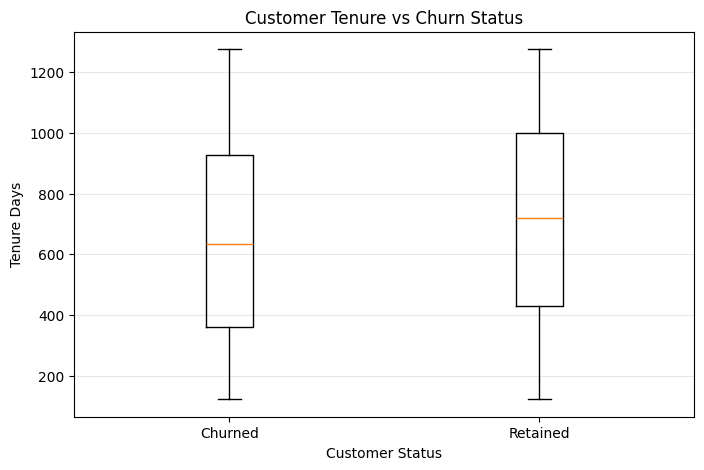

In [31]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        churned['tenure_days'].dropna(),
        retained['tenure_days'].dropna()
    ],
    tick_labels=['Churned', 'Retained']
)

plt.title('Customer Tenure vs Churn Status')
plt.ylabel('Tenure Days')
plt.xlabel('Customer Status')

plt.grid(axis='y', alpha=0.3)
plt.show()

**Q25. Recharge-active customers**

In [32]:
active_customers = validation_df[
    validation_df['recharge_count'] > 0
]

active_churned = active_customers[
    active_customers['is_churned'] == 1
]

active_retained = active_customers[
    active_customers['is_churned'] == 0
]

**Q26. Total recharge comparison**

In [33]:
stats.ttest_ind(
    active_churned['total_recharge'],
    active_retained['total_recharge'],
    equal_var=False
)

TtestResult(statistic=np.float64(-42.32270453235038), pvalue=np.float64(0.0), df=np.float64(9739.78638918568))

**Q27. Customer summary**

In [34]:
print("Total Subscribers:", len(validation_df))

print("Unique Customers:",
      validation_df['customer_id'].nunique())

print("Churned Customers:", len(churned))

print("Retained Customers:", len(retained))

print("Recharge Active Customers:",
      len(active_customers))

Total Subscribers: 22000
Unique Customers: 22000
Churned Customers: 5226
Retained Customers: 16774
Recharge Active Customers: 18289
